In [54]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt

In [4]:
train_df = pd.read_csv("data/raw/fraudTrain.csv")
test_df = pd.read_csv("data/raw/fraudTest.csv")

In [32]:
train_df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [5]:
len(train_df), len(test_df)

(1296675, 555719)

In [6]:
train_df.shape, test_df.shape

((1296675, 23), (555719, 23))

In [10]:
train_df.is_fraud.mean()

np.float64(0.005788651743883394)

In [11]:
test_df.is_fraud.mean()

np.float64(0.0038598644278853163)

In [16]:
train_df.isnull().sum()

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

In [17]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  str    
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  str    
 4   category               1296675 non-null  str    
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  str    
 7   last                   1296675 non-null  str    
 8   gender                 1296675 non-null  str    
 9   street                 1296675 non-null  str    
 10  city                   1296675 non-null  str    
 11  state                  1296675 non-null  str    
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long                   129667

In [18]:
train_df.describe()

,Unnamed: 0,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,3.743180e+05,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,0.000000e+00,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,3.241685e+05,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,1.296674e+06,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


In [19]:
train_df.duplicated(subset="trans_num").sum()

np.int64(0)

In [20]:
train_df.amt.describe()

count    1.296675e+06
mean     7.035104e+01
std      1.603160e+02
min      1.000000e+00
25%      9.650000e+00
50%      4.752000e+01
75%      8.314000e+01
max      2.894890e+04
Name: amt, dtype: float64

In [21]:
train_df.trans_date_trans_time.min(), train_df.trans_date_trans_time.max()

('2019-01-01 00:00:18', '2020-06-21 12:13:37')

In [23]:
train_df[["lat","long","merch_lat","merch_long"]].describe()

,lat,long,merch_lat,merch_long
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,3.853762e+01,-9.022634e+01,3.853734e+01,-9.022646e+01
std,5.075808e+00,1.375908e+01,5.109788e+00,1.377109e+01
min,2.002710e+01,-1.656723e+02,1.902779e+01,-1.666712e+02
25%,3.462050e+01,-9.679800e+01,3.473357e+01,-9.689728e+01
50%,3.935430e+01,-8.747690e+01,3.936568e+01,-8.743839e+01
75%,4.194040e+01,-8.015800e+01,4.195716e+01,-8.023680e+01
max,6.669330e+01,-6.795030e+01,6.751027e+01,-6.695090e+01


In [24]:
train_df.dob.min(), train_df.dob.max()

('1924-10-30', '2005-01-29')

In [26]:
train_df.groupby("is_fraud").amt.describe().round(2)

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,67.67,154.01,1.00,9.61,47.28,82.54,28948.90
1,7506.0,531.32,390.56,1.06,245.66,396.50,900.88,1376.04


In [28]:
train_df['trans_date_trans_time'] = pd.to_datetime(train_df['trans_date_trans_time'])

In [29]:
train_df.groupby(train_df.trans_date_trans_time.dt.hour).is_fraud.mean().round(4)

trans_date_trans_time
0     0.0149
1     0.0153
2     0.0147
3     0.0142
4     0.0011
5     0.0014
6     0.0009
7     0.0013
8     0.0012
9     0.0011
10    0.0009
11    0.0010
12    0.0010
13    0.0012
14    0.0013
15    0.0012
16    0.0012
17    0.0012
18    0.0012
19    0.0012
20    0.0010
21    0.0011
22    0.0288
23    0.0284
Name: is_fraud, dtype: float64

In [30]:
train_df.groupby("category").is_fraud.mean().sort_values(ascending=False).round(4)

category
shopping_net      0.0176
misc_net          0.0145
grocery_pos       0.0141
shopping_pos      0.0072
gas_transport     0.0047
misc_pos          0.0031
grocery_net       0.0029
travel            0.0029
entertainment     0.0025
personal_care     0.0024
kids_pets         0.0021
food_dining       0.0017
home              0.0016
health_fitness    0.0015
Name: is_fraud, dtype: float64

In [31]:
train_df.cc_num.nunique()

983

In [34]:
# print(train_df.duplicated(subset="trans_num").sum())   # duplicate transactions
# print(train_df.amt.describe())                         # negative, zero or extreme amounts?
# print(train_df.trans_date_trans_time.min(), train_df.trans_date_trans_time.max())   # date range sensible?
# print(train_df[["lat","long","merch_lat","merch_long"]].describe())              # coordinates in valid ranges?
# print(train_df.dob.min(), train_df.dob.max())             # ages sensible?

In [35]:
# print(train_df.groupby("is_fraud").amt.describe().round(2))
# print(train_df.groupby(train_df.trans_date_trans_time.dt.hour).is_fraud.mean().round(4))
# print(train_df.groupby("category").is_fraud.mean().sort_values(ascending=False).round(4))
# print(train_df.cc_num.nunique())

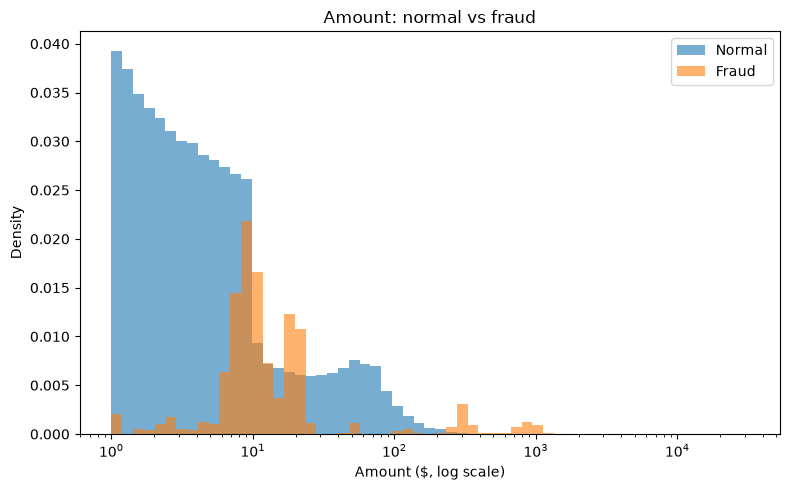

In [55]:
# 1. Amount distribution, normal vs fraud (log scale since amounts are skewed)
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.logspace(0, 4.5, 60)
ax.hist(train_df[train_df.is_fraud == 0].amt, bins=bins, alpha=0.6, density=True, label="Normal")
ax.hist(train_df[train_df.is_fraud == 1].amt, bins=bins, alpha=0.6, density=True, label="Fraud")
ax.set_xscale("log")
ax.set(title="Amount: normal vs fraud", xlabel="Amount ($, log scale)", ylabel="Density")
ax.legend()
fig.tight_layout()
fig.savefig("data/reports/amount_distribution.png", dpi=150)
plt.show()

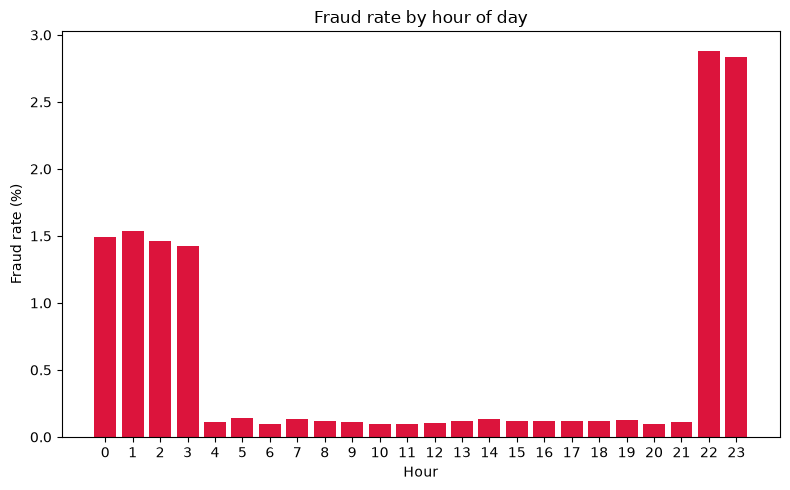

In [57]:
# 2. Fraud rate by hour
train_df["hour"] = train_df["trans_date_trans_time"].dt.hour
fig, ax = plt.subplots(figsize=(8, 5))
hourly = train_df.groupby("hour").is_fraud.mean() * 100
ax.bar(hourly.index, hourly.values, color="crimson")
ax.set(title="Fraud rate by hour of day", xlabel="Hour", ylabel="Fraud rate (%)")
ax.set_xticks(range(24))
fig.tight_layout()
fig.savefig("data/reports/fraud_by_hour.png", dpi=150)
plt.show()


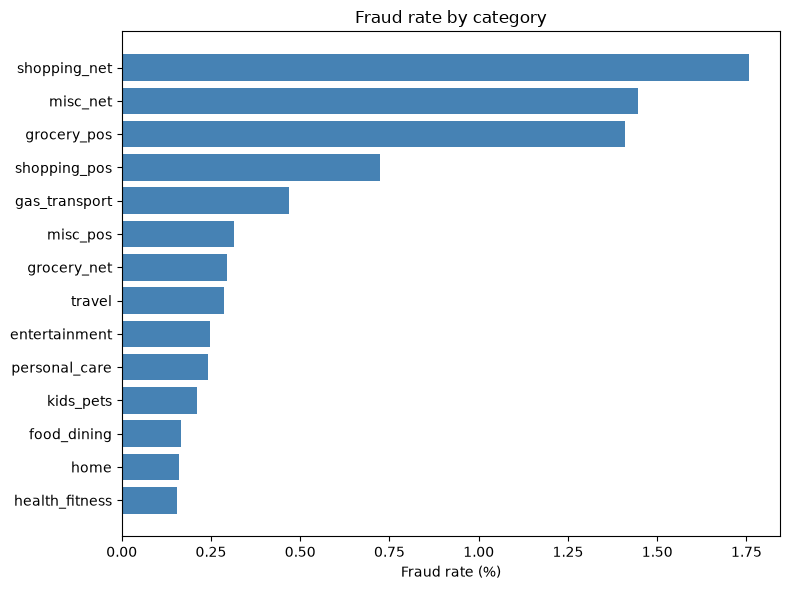

In [60]:
# 3. Fraud rate by category
fig, ax = plt.subplots(figsize=(8, 6))
cat = (train_df.groupby("category").is_fraud.mean() * 100).sort_values()
ax.barh(cat.index, cat.values, color="steelblue")
ax.set(title="Fraud rate by category", xlabel="Fraud rate (%)")
fig.tight_layout()
fig.savefig("data/reports/fraud_by_category.png", dpi=150)
plt.show()

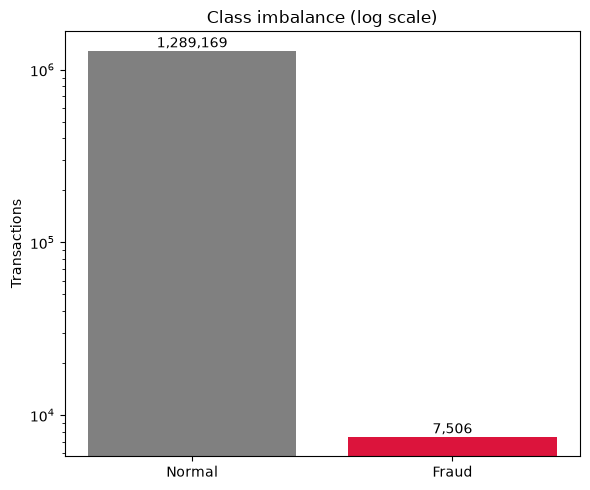

In [61]:
# 4. Class imbalance
fig, ax = plt.subplots(figsize=(6, 5))
counts = train_df.is_fraud.value_counts().sort_index()
ax.bar(["Normal", "Fraud"], counts.values, color=["gray", "crimson"])
ax.set_yscale("log")
ax.set(title="Class imbalance (log scale)", ylabel="Transactions")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
fig.tight_layout()
fig.savefig("data/reports/class_imbalance.png", dpi=150)
plt.show()

In [62]:
train_df.is_fraud.value_counts()

is_fraud
0    1289169
1       7506
Name: count, dtype: int64